In [82]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import pandas as pd

In [83]:
ds_full = load_dataset("Artificio/WikiArt_Full", split="train", cache_dir="data")

Note that normalization happened before deduping step which could be a mistake but I've checked and in this dataset it wont change anything (with exception of artist conflict which is small) as deduping is made solely on hashed pixels and deletion is decided by amount of not None fields not their contents. And in preprocessing pipleine this mistake is actually fixed making so that there is no conflict when Artist's name is not normalized during for a duplicated img.

# General info

In [84]:
print(ds_full)                # features + num_rows
print(len(ds_full))           # 103250
print(ds_full.column_names)
print(ds_full.features)       # types per column
print(ds_full.info.description)

Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats'],
    num_rows: 103250
})
103250
['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats']
{'title': Value('string'), 'artist': Value('string'), 'date': Value('string'), 'genre': Value('string'), 'style': Value('string'), 'description': Value('string'), 'filename': Value('string'), 'image': Image(mode=None, decode=True), 'embeddings_pca512': List(Value('float32')), 'resnet50_non_robust_feats': List(Value('float32')), 'resnet50_robust_feats': List(Value('float32'))}



In [85]:
print(ds_full.info)

DatasetInfo(features={'title': Value('string'), 'artist': Value('string'), 'date': Value('string'), 'genre': Value('string'), 'style': Value('string'), 'description': Value('string'), 'filename': Value('string'), 'image': Image(mode=None, decode=True), 'embeddings_pca512': List(Value('float32')), 'resnet50_non_robust_feats': List(Value('float32')), 'resnet50_robust_feats': List(Value('float32'))}, builder_name='parquet', dataset_name='wiki_art_full', config_name='default', version=0.0.0, splits={'train': SplitInfo(name='train', num_bytes=3411668192, num_examples=103250, shard_lengths=[15750, 15750, 15750, 15750, 15750, 15750, 8750], dataset_name='wiki_art_full')}, download_size=3245866583, dataset_size=3411668192, size_in_bytes=6657534775)


# View img

Column([<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1DDCDB2ADB0>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1DDCDB2A540>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1DDCDB2A990>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1DDCDB28AD0>, <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=256x256 at 0x1DDCDB2A810>, ...])
(256, 256)


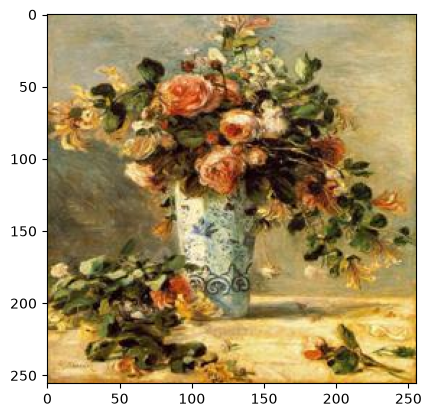

In [86]:
print(ds_full['image'])
print(ds_full['image'][79082].size)
plt.imshow(ds_full['image'][79082])

# Check counts

In [87]:
styles = ds_full.unique("style")
print(len(styles))
Counter(ds_full['style'])

137


Counter({'Impressionism': 10643,
         'Realism': 10523,
         'Romanticism': 9285,
         'Expressionism': 7013,
         'Post-Impressionism': 5778,
         'Art Nouveau (Modern)': 4899,
         'Baroque': 4400,
         'Surrealism': 4167,
         'Symbolism': 3476,
         'Rococo': 2733,
         'Northern Renaissance': 2379,
         'Naïve Art (Primitivism)': 2295,
         'Abstract Expressionism': 2074,
         'Neoclassicism': 2038,
         'Cubism': 1747,
         'Ukiyo-e': 1426,
         'Early Renaissance': 1351,
         'Mannerism (Late Renaissance)': 1342,
         'High Renaissance': 1314,
         'Art Informel': 1267,
         'Magic Realism': 1002,
         'None': 986,
         'Abstract Art': 979,
         'Academicism': 972,
         'Color Field Painting': 910,
         'Pop Art': 791,
         'Fauvism': 731,
         'Lyrical Abstraction': 670,
         'Art Deco': 644,
         'Concretism': 581,
         'Neo-Romanticism': 566,
         'Ink a

count      137.000000
mean       753.649635
std       1794.764037
min          1.000000
25%         36.000000
50%        137.000000
75%        460.000000
max      10643.000000
dtype: float64
Styles with fewer than 50 examples: 45


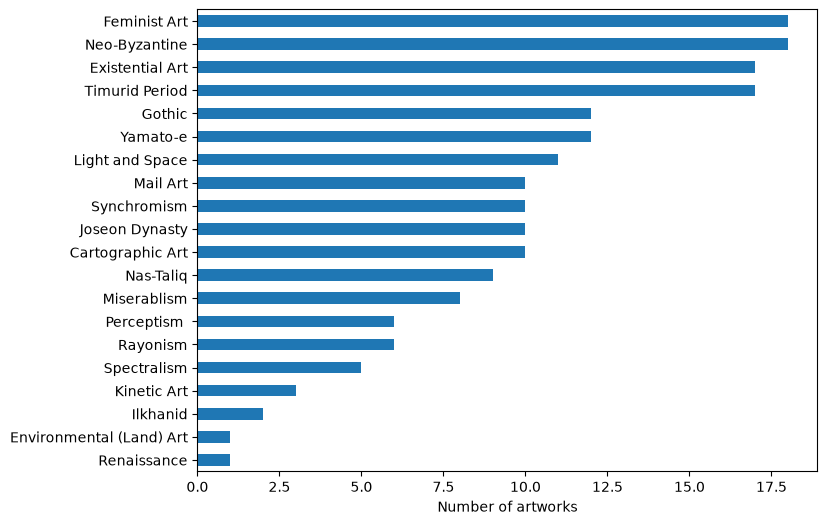

In [88]:
counts = pd.Series(Counter(ds_full["style"])).sort_values(ascending=False)
print(counts.describe())
print("Styles with fewer than 50 examples:", (counts < 50).sum())

counts.tail(20).sort_values().plot.barh(figsize=(8, 6))
plt.xlabel("Number of artworks")
plt.show()

# Making sure sizes match

In [89]:
sizes_set = set()
for img in ds_full['image']:
    sizes_set.add(img.size)

len(sizes_set)

1

# Check duplicate imgs

309 exact-duplicate groups
31 groups with conflicting style labels


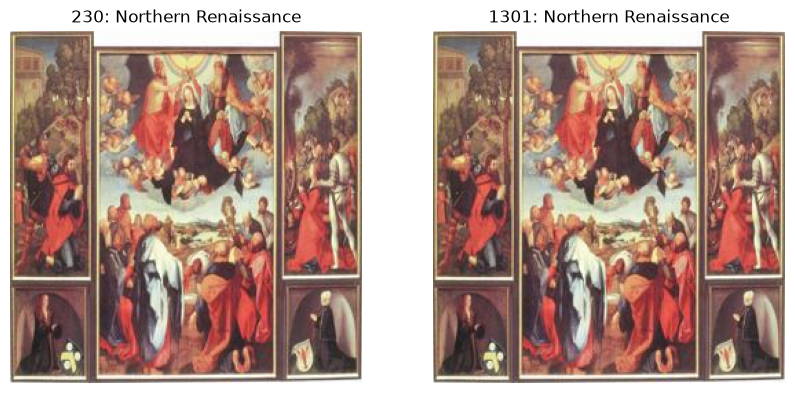

In [90]:
from collections import defaultdict
import hashlib

hash_to_indices = defaultdict(list)

for idx, img in enumerate(ds_full['image']):
    h = hashlib.sha256(img.tobytes()).hexdigest()
    hash_to_indices[h].append(idx)

exact_groups = [g for g in hash_to_indices.values() if len(g) > 1]
print(f"{len(exact_groups)} exact-duplicate groups")

# Duplicates with conflicting labels
styles = ds_full["style"]
conflicts = [g for g in exact_groups if len({styles[i] for i in g}) > 1]
print(f"{len(conflicts)} groups with conflicting style labels")

# Show a real duplicate pair
a, b = exact_groups[0][:2]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, idx in zip(axes, (a, b)):
    ax.imshow(ds_full[idx]["image"]); ax.set_title(f"{idx}: {styles[idx]}"); ax.axis("off")
plt.show()

In [91]:
from collections import Counter

n_groups    = len(exact_groups)
n_in_groups = sum(len(g) for g in exact_groups)        # every image that has at least one twin
n_redundant = sum(len(g) - 1 for g in exact_groups)    # extra copies, i.e. what dedup removes
N = len(ds_full)

print(f"Duplicate groups:                {n_groups}")
print(f"Images involved in duplicates:   {n_in_groups} ({n_in_groups / N:.2%})")
print(f"Redundant copies (to remove):    {n_redundant} ({n_redundant / N:.2%})")
print(f"Unique images after dedup:       {N - n_redundant}")

# Group size distribution
print("Group size -> number of groups:", dict(sorted(Counter(len(g) for g in exact_groups).items())))

Duplicate groups:                309
Images involved in duplicates:   657 (0.64%)
Redundant copies (to remove):    348 (0.34%)
Unique images after dedup:       102902
Group size -> number of groups: {2: 291, 3: 8, 4: 7, 5: 1, 9: 2}


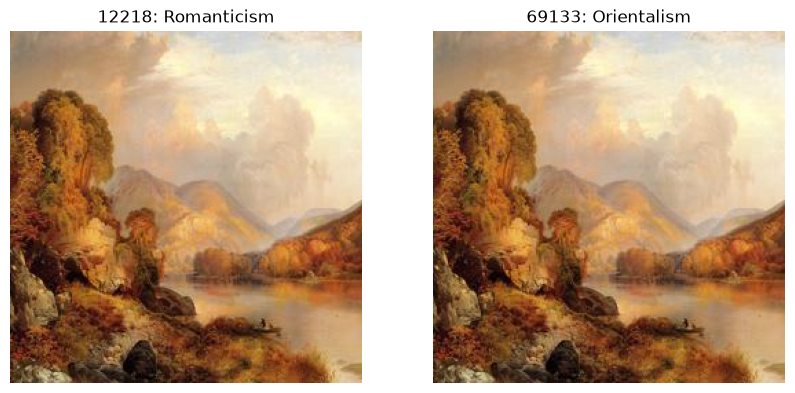

In [92]:
# Show a real duplicate pair
a, b = conflicts[4][:2]
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, idx in zip(axes, (a, b)):
    ax.imshow(ds_full[idx]["image"]); ax.set_title(f"{idx}: {styles[idx]}"); ax.axis("off")
plt.show()

# Resolving dup conflicts

In [93]:
# Metadata only (no image decoding, so this is fast)
meta : pd.DataFrame = ds_full.remove_columns("image").to_pandas()
cols = ["title", "artist", "date", "genre", "style"]


def differing_cols(g):
    """Return the metadata columns that are not identical across the group."""
    return [c for c in cols if meta.loc[g, c].nunique(dropna=False) > 1]

# Annotate each group
group_info = [(g, differing_cols(g)) for g in exact_groups]

# Summary: which columns differ, and how often
from collections import Counter
print(Counter(tuple(d) for _, d in group_info).most_common())

def show_groups(groups, max_groups=20):
    for n, (g, diff) in enumerate(groups[:max_groups], 1):
        print(f"\n=== Group {n} | size {len(g)} | differing: {diff or 'none'} ===")
        print(meta.loc[g, cols].to_string())

# 1) Groups where style conflicts (what you care about most)
style_conflicts = [(g, d) for g, d in group_info if "style" in d]
print(f"\n{len(style_conflicts)} groups with style conflicts")
show_groups(style_conflicts, max_groups=30)

# 2) A sample of groups with no conflict at all, as a sanity check
clean = [(g, d) for g, d in group_info if not d]
print(f"\n{len(clean)} groups fully identical in metadata")
show_groups(clean, max_groups=5)

# 3) Groups where other columns differ but style does not
other = [(g, d) for g, d in group_info if d and "style" not in d]
print(f"\n{len(other)} groups differing only in non-style columns")
show_groups(other, max_groups=10)

[((), 101), (('title',), 66), (('title', 'date'), 55), (('title', 'date', 'genre'), 11), (('date',), 11), (('genre',), 9), (('title', 'genre'), 8), (('title', 'date', 'genre', 'style'), 7), (('title', 'artist', 'date'), 6), (('title', 'genre', 'style'), 4), (('title', 'style'), 4), (('title', 'artist'), 4), (('title', 'artist', 'date', 'style'), 3), (('title', 'date', 'style'), 3), (('genre', 'style'), 3), (('style',), 3), (('title', 'artist', 'style'), 2), (('title', 'artist', 'genre'), 2), (('title', 'artist', 'date', 'genre'), 1), (('artist', 'date', 'genre'), 1), (('artist', 'date', 'genre', 'style'), 1), (('artist',), 1), (('artist', 'date'), 1), (('date', 'genre'), 1), (('date', 'style'), 1)]

31 groups with style conflicts

=== Group 1 | size 2 | differing: ['title', 'date', 'genre', 'style'] ===
                  title                artist    date                  genre          style
2745   Venus und Adonis  Pierre-Paul Prud'hon  c.1800  mythological painting    Romanticism
4

In [94]:
import random

SEED = 42
rng = random.Random(SEED)
cols = ["title", "artist", "date", "genre", "style"]
# label_cols = ["artist", "date", "genre", "style"]
meta["n_missing"] = meta[cols].isna().sum(axis=1)

drop, label_unreliable = set(), set()

for g in sorted(exact_groups):                 # fixed order -> reproducible
    best = meta.loc[g, "n_missing"].min()
    tied = [i for i in g if meta.at[i, "n_missing"] == best]
    keeper = rng.choice(tied)                  # only random if there is a tie
    drop.update(i for i in g if i != keeper)

    # artist conflict -> record likely wrong -> null all labels
    if meta.loc[g, "artist"].dropna().nunique() > 1:
        label_unreliable.add(keeper)

keep = [i for i in range(len(ds_full)) if i not in drop]

null_cols = ["artist", "date", "genre", "style", "description"]

def null_labels(artist, date, genre, style, description, idx):
    if idx in label_unreliable:
        return dict(artist=None, date=None, genre=None, style=None, description=None)
    return dict(artist=artist, date=date, genre=genre, style=style, description=description)

ds_clean = ds_full.map(
    null_labels,
    input_columns=null_cols,
    with_indices=True,
    features=ds_full.features,
)

ds_dedup = ds_clean.select(keep)

In [95]:
print(type(ds_dedup))

<class 'datasets.arrow_dataset.Dataset'>


In [102]:
# ds_full['image'][230].show()
# ds_full['image'][1301].show()
# ds_dedup['image'][1301].show()
# print(ds_dedup[230])

In [97]:
print(len(ds_full))
print(len(ds_dedup))

103250
102902


# Cleaning date label and maybe other if required

### checkign if normalization required

In [98]:
import re
import unicodedata
from collections import defaultdict

import pandas as pd

cols = ["title", "artist", "date", "genre", "style"]
meta = ds_full.select_columns(cols).to_pandas()

def normalize_value(value, column):
    text = unicodedata.normalize("NFKC", str(value))
    text = " ".join(text.split()).casefold()

    if column == "date":
        # Treat common circa prefixes as equivalent.
        text = re.sub(r"^(?:c(?:irca)?\.?|ca\.?|approx\.?)\s*", "", text)
        # Treat a year stored as a float-like string as an integer year.
        text = re.sub(r"^(\d{1,4})\.0$", r"\1", text)

    return text

matches = []

for column in cols:
    groups = defaultdict(lambda: defaultdict(int))

    for value in meta[column].dropna():
        raw_value = str(value)
        normalized = normalize_value(value, column)
        groups[normalized][raw_value] += 1

    for normalized, variants in groups.items():
        if len(variants) > 1:
            matches.append({
                "column": column,
                "normalized_value": normalized,
                "variants_and_counts": dict(variants),
            })

candidates = pd.DataFrame(matches)

if candidates.empty:
    print("No normalization-based inconsistencies found.")
else:
    display(candidates.sort_values(["column", "normalized_value"]))

,column,normalized_value,variants_and_counts
2198,artist,church of the covenant (boston),"{'Church of the Covenant (Boston) ': 16, 'Chur..."
2200,artist,driven by the spirit,"{'Driven by the spirit': 1, 'Driven by the Spi..."
2202,artist,evening,"{'Evening': 1, 'Evening ': 1}"
2205,artist,jester,"{'Jester': 1, ' Jester': 1}"
2203,artist,jetty,"{'Jetty ': 1, 'Jetty': 1}"
...,...,...,...
1237,title,youth,"{'Youth': 5, 'Youth ': 1}"
599,title,yvette guilbert,"{'Yvette Guilbert ': 1, 'Yvette Guilbert': 7}"
373,title,zebra,"{'Zebra': 5, 'Zebra ': 1}"
2072,title,zhen sanli,"{'Zhen Sanli ': 1, 'Zhen Sanli': 1}"


In [99]:
display(candidates[candidates['column'] == 'title'])

,column,normalized_value,variants_and_counts
0,title,milking the cow,"{'Milking the Cow ': 1, 'Milking the Cow': 1}"
1,title,self-portrait,"{'Self-portrait': 230, 'Self-Portrait': 341, '..."
2,title,winter,"{'Winter': 38, 'Winter ': 11}"
3,title,a classical landscape,"{'A Classical Landscape ': 1, 'A Classical Lan..."
4,title,untitled,"{'Untitled': 2231, 'Untitled ': 48, 'Untitled ..."
...,...,...,...
2192,title,laburnum,"{'Laburnum': 1, 'Laburnum ': 1}"
2193,title,christian martyrs in the colosseum,"{'Christian martyrs in the Colosseum ': 1, 'Ch..."
2194,title,madonna and child enthroned with two angels,{'Madonna and Child Enthroned with Two Angels ...
2195,title,l'atelier,"{'L'atelier': 1, 'L'Atelier': 1}"


In [100]:
def normalize_row(row):
    return {
        col: (
            normalize_value(row[col], col) if row[col] is not None else None
        )
        for col in cols
    }

ds_dedup_normalized = ds_dedup.map(normalize_row)
print(type(ds_dedup_normalized))

Map: 100%|██████████| 102902/102902 [01:00<00:00, 1696.17 examples/s]

<class 'datasets.arrow_dataset.Dataset'>


In [101]:
print(ds_full)
print(ds_dedup)
print(ds_dedup_normalized)

Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats'],
    num_rows: 103250
})
Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats'],
    num_rows: 102902
})
Dataset({
    features: ['title', 'artist', 'date', 'genre', 'style', 'description', 'filename', 'image', 'embeddings_pca512', 'resnet50_non_robust_feats', 'resnet50_robust_feats'],
    num_rows: 102902
})
